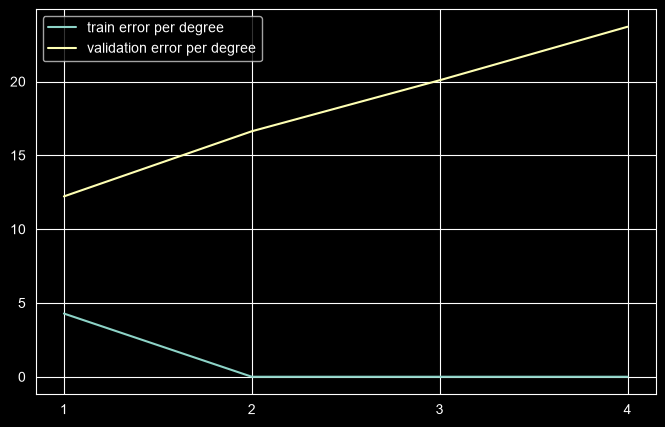

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler , PolynomialFeatures
from sklearn.metrics import root_mean_squared_error

### Data reading
np.random.seed(17)
data = pd.read_csv(r'data2_200x30.csv')

## Data splitting

x = data.iloc[:, :-1]
y = data.iloc[:, -1]

x_train =x.iloc[:100]
x_val =x.iloc[100:]
y_train =y.iloc[:100]
y_val =y.iloc[100:]

degrees = [1,2,3,4]
train_rmse =[]
val_rmse = []

## polynomial features
for degree in degrees:
    poly = PolynomialFeatures(degree = degree , include_bias = False)
    x_train_poly = poly.fit_transform(x_train)
    x_val_poly = poly.transform(x_val)


    ##scaling

    scaler = MinMaxScaler()
    x_train_poly_scaled = scaler.fit_transform(x_train_poly)
    x_val_poly_scaled = scaler.transform(x_val_poly)

    ### creating linear regression model
    model = LinearRegression()
    ## training model
    model.fit(x_train_poly_scaled, y_train)
    ## predict on training data

    y_train_pred = model.predict(x_train_poly_scaled)

    ## predict on validation data

    y_val_pred = model.predict(x_val_poly_scaled)


    ### calculate training error

    train_error = root_mean_squared_error(y_train , y_train_pred)

    ### calculate training error

    val_error = root_mean_squared_error(y_val , y_val_pred)

    train_rmse .append(train_error)
    val_rmse .append(val_error)



## graph

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rmse,label="train error per degree")
plt.plot(degrees , val_rmse , label="validation error per degree")
plt.xticks(degrees)
plt.legend()
